# TA5 — Part 2: Regression
**Author:** Whitty, Juan Angelo Roy B <br>
Ebrahim, Fathi Mahad 
<br>**Dataset:** `datasets/Boston-1.csv`  
**Model:** Random Forest Regressor

This notebook assesses the continuous target distribution, compares three validation
schemes, tunes at least three hyperparameters using grid search and Bayesian
optimization, and reports R², MAE, MSE, and RMSE. All conclusions use executed results.

## 1. Setup and reproducibility
Run all cells in order with the lab directory as the working directory. If needed,
install dependencies in the notebook's Python environment with
`python -m pip install numpy pandas scikit-learn matplotlib seaborn optuna nbformat nbclient ipykernel`.
No cell installs packages automatically. The versions below identify the executed environment.

Cross-validation uses at most two joblib threads to avoid process-cleanup issues on Windows; individual forests use one job.

In [1]:
from pathlib import Path
import os
import platform
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
from joblib import parallel_config
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import (
    train_test_split, KFold, StratifiedKFold, ShuffleSplit,
    cross_validate, GridSearchCV,
)
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, root_mean_squared_error

SEED = 42
N_JOBS = min(2, os.cpu_count() or 1)
DATA_PATH = Path('datasets/Boston-1.csv')
assert DATA_PATH.is_file(), 'Run this notebook from the ta3 lab directory.'
pd.set_option('display.max_columns', 20)
sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.figsize': (10, 5), 'figure.dpi': 120, 'font.size': 11})
optuna.logging.set_verbosity(optuna.logging.WARNING)
versions = {'Python': platform.python_version()}
versions.update({p: version(p) for p in ['numpy', 'pandas', 'scikit-learn', 'matplotlib', 'seaborn', 'optuna']})
display(pd.Series(versions, name='Executed version').to_frame())

C:\Users\yuanw\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Executed version
Python,3.14.7
numpy,2.5.3
pandas,3.0.6
scikit-learn,1.9.1
matplotlib,3.11.2
seaborn,0.13.2
optuna,5.0.0


## 2. Load and inspect the data
`medv` is the regression target. The unnamed first column is a sequential row ID,
not a predictive feature. Remove only this ID; retain all 13 numeric predictors.
The checks explicitly stop on unexpected missing or nonnumeric data rather than
silently changing the dataset. Random Forest does not require feature scaling.

In [2]:
raw = pd.read_csv(DATA_PATH)
id_column = raw.columns[0]
assert id_column.startswith('Unnamed:')
assert raw[id_column].tolist() == list(range(1, len(raw) + 1))
data = raw.drop(columns=[id_column])
assert data.shape == (506, 14)
assert data.isna().sum().sum() == 0
assert all(pd.api.types.is_numeric_dtype(dtype) for dtype in data.dtypes)
assert np.isfinite(data.to_numpy()).all()
X = data.drop(columns='medv')
y = data['medv']
audit = pd.DataFrame({
    'Check': ['Rows', 'Predictors', 'Missing values', 'Duplicate rows (excluding ID)', 'Duplicate predictor rows'],
    'Result': [len(data), X.shape[1], int(data.isna().sum().sum()), int(data.duplicated().sum()), int(X.duplicated().sum())],
})
display(audit)
display(data.head())
display(y.describe().to_frame('medv'))

,Check,Result
0,Rows,506
1,Predictors,13
2,Missing values,0
3,Duplicate rows (excluding ID),0
4,Duplicate predictor rows,0


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


,medv
count,506.000000
mean,22.532806
std,9.197104
min,5.000000
25%,17.025000
50%,21.200000
75%,25.000000
max,50.000000


## 3. Is the regression dataset balanced?
For a continuous target, balance concerns representation across target ranges;
there are no classification labels and no universal balance threshold. We use
**ten equal-width bins** over the observed range and show each bin's count and
percentage, plus skewness and the largest-to-smallest occupied-bin count ratio.
These are descriptive diagnostics; bin choice affects the ratio.

Quantile bins would contain roughly equal counts by construction, so they would
conceal the uneven density being assessed here. Later, separate quantile bins are
used only to make stratified regression splits. No resampling or target conversion
is applied to model training. This full-dataset plot is descriptive; model decisions
and tuning use only the training partition.

The histogram and count chart use the same right-closed bin counts, including observations exactly on internal bin boundaries.

,Count,Percentage
medv,,
"(4.999, 9.5]",22,4.35
"(9.5, 14.0]",55,10.87
"(14.0, 18.5]",85,16.80
"(18.5, 23.0]",154,30.43
"(23.0, 27.5]",84,16.60
"(27.5, 32.0]",39,7.71
"(32.0, 36.5]",29,5.73
"(36.5, 41.0]",7,1.38
"(41.0, 45.5]",10,1.98


Mean: 22.5328; median: 21.2000; skewness: 1.1081
Largest/smallest occupied-bin count: 154/7 = 22.00:1
Observations at the observed maximum (50): 16


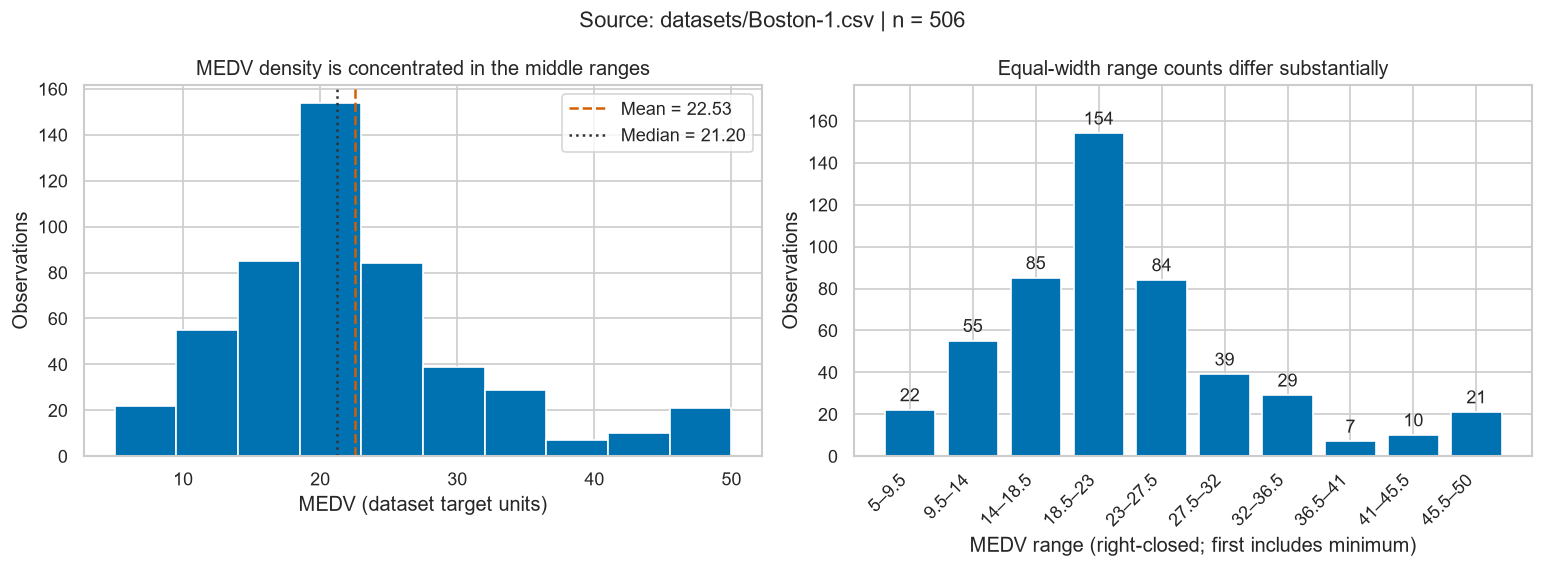

**Conclusion:** The target distribution is **imbalanced across equal-width ranges**, with a 22:1 occupied-bin count ratio and positive skewness of 1.108. Central values are better represented than some extreme ranges. This describes regression target density, not an imbalance between classes. All observations are retained.

In [3]:
edges = np.linspace(y.min(), y.max(), 11)
counts = pd.cut(y, bins=edges, include_lowest=True).value_counts(sort=False)
balance_table = pd.DataFrame({'Count': counts, 'Percentage': 100 * counts / len(y)})
imbalance_ratio = float(counts.max() / counts[counts > 0].min())
target_skew = float(y.skew())
display(balance_table.round(2))
print(f'Mean: {y.mean():.4f}; median: {y.median():.4f}; skewness: {target_skew:.4f}')
print(f'Largest/smallest occupied-bin count: {counts.max()}/{counts[counts > 0].min()} = {imbalance_ratio:.2f}:1')
print(f'Observations at the observed maximum ({y.max():g}): {int(y.eq(y.max()).sum())}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].bar(edges[:-1], counts.to_numpy(), width=np.diff(edges), align='edge', color='#0072B2', edgecolor='white')
axes[0].axvline(y.mean(), color='#D55E00', linestyle='--', label=f'Mean = {y.mean():.2f}')
axes[0].axvline(y.median(), color='#333333', linestyle=':', label=f'Median = {y.median():.2f}')
axes[0].set(title='MEDV density is concentrated in the middle ranges', xlabel='MEDV (dataset target units)', ylabel='Observations')
axes[0].legend()
positions = np.arange(len(counts))
bars = axes[1].bar(positions, counts, color='#0072B2')
axes[1].bar_label(bars, padding=3)
axes[1].set_xticks(positions, [f'{edges[i]:g}–{edges[i+1]:g}' for i in positions], rotation=45, ha='right')
axes[1].set(title='Equal-width range counts differ substantially', xlabel='MEDV range (right-closed; first includes minimum)', ylabel='Observations', ylim=(0, counts.max() * 1.15))
fig.suptitle('Source: datasets/Boston-1.csv | n = 506')
plt.tight_layout()
plt.show()
display(Markdown(
    f'**Conclusion:** The target distribution is **imbalanced across equal-width ranges**, '
    f'with a {imbalance_ratio:.0f}:1 occupied-bin count ratio and positive skewness of {target_skew:.3f}. '
    'Central values are better represented than some extreme ranges. This describes regression target density, '
    'not an imbalance between classes. All observations are retained.'
))

## 4. Hold-out partition and cross-validation
Reserve an unstratified 20% test partition with seed 42. It is excluded from all
hyperparameter searches and final model selection. Five-fold shuffled K-fold and
five repeated 80/20 ShuffleSplit splits use training rows only.

`StratifiedKFold` requires categorical strata, so we form five training-target
quantile bins and pass them **only to the splitter**. Its materialized indices
then select the original continuous targets for fitting and scoring. The bin labels
never become predictors or predicted classes. Each validation method's exact splits
are reused for the baseline, grid search, and Bayesian optimization.

ShuffleSplit validation sets can overlap across repetitions. Reported standard
deviations describe split variability; they are not independent-sample confidence intervals.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)
assert len(X_train) == 404 and len(X_test) == 102
assert set(X_train.index).isdisjoint(X_test.index)
strata = pd.qcut(y_train, q=5, labels=False, duplicates='drop')
assert strata.nunique() == 5 and strata.value_counts().min() >= 5
cv_splits = {
    'K-fold': list(KFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train)),
    'Stratified K-fold': list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train, strata)),
    'Shuffle split': list(ShuffleSplit(n_splits=5, test_size=0.20, random_state=SEED).split(X_train)),
}
split_audit = []
for scheme, splits in cv_splits.items():
    for fold, (train_idx, val_idx) in enumerate(splits, 1):
        assert set(train_idx).isdisjoint(val_idx)
        assert len(train_idx) + len(val_idx) == len(X_train)
        split_audit.append({'CV': scheme, 'Split': fold, 'Train rows': len(train_idx), 'Validation rows': len(val_idx)})
    if scheme != 'Shuffle split':
        assert sorted(np.concatenate([v for _, v in splits]).tolist()) == list(range(len(X_train)))
print(f'Training rows: {len(X_train)}; untouched test rows: {len(X_test)}')
display(pd.Series(strata.value_counts().sort_index(), name='Training rows per quantile bin').to_frame())
display(pd.DataFrame(split_audit))
strata_distribution = pd.DataFrame({
    f'Fold {i}': strata.iloc[v].value_counts(normalize=True).sort_index()
    for i, (_, v) in enumerate(cv_splits['Stratified K-fold'], 1)
}).T
display((100 * strata_distribution).round(2).rename_axis('Stratified validation fold').rename(columns=lambda c: f'Bin {c} (%)'))

Training rows: 404; untouched test rows: 102


,Training rows per quantile bin
medv,
0,82
1,81
2,82
3,79
4,80


,CV,Split,Train rows,Validation rows
0,K-fold,1,323,81
1,K-fold,2,323,81
2,K-fold,3,323,81
3,K-fold,4,323,81
4,K-fold,5,324,80
5,Stratified K-fold,1,323,81
6,Stratified K-fold,2,323,81
7,Stratified K-fold,3,323,81
8,Stratified K-fold,4,323,81
9,Stratified K-fold,5,324,80


medv,Bin 0 (%),Bin 1 (%),Bin 2 (%),Bin 3 (%),Bin 4 (%)
Stratified validation fold,,,,,
Fold 1,20.99,19.75,19.75,19.75,19.75
Fold 2,20.99,19.75,19.75,19.75,19.75
Fold 3,19.75,20.99,20.99,18.52,19.75
Fold 4,19.75,19.75,20.99,19.75,19.75
Fold 5,20.00,20.00,20.00,20.00,20.00


## 5. Random Forest and metric definitions
Random Forest averages decision trees, allowing nonlinear relationships and feature
interactions without scaling. Its tree count, depth, and minimum leaf size provide
three interpretable tuning controls for stability and model complexity.

- **R²:** explained variation relative to a mean predictor; higher is better and values can be negative.
- **MAE:** mean absolute error in target units; lower is better.
- **MSE:** mean squared error in squared target units; lower is better.
- **RMSE:** square root of MSE in target units; lower is better and large errors receive greater weight than in MAE.

Scikit-learn uses negative error scorers so that larger scores are always preferred.
We reverse their signs for all displayed error metrics. Selection minimizes mean
validation RMSE. Mean fold RMSE is not generally the square root of mean fold MSE;
the identity is checked within each individual fold instead.

In [5]:
METRICS = ['R2', 'MAE', 'MSE', 'RMSE']
SCORING = {'R2': 'r2', 'MAE': 'neg_mean_absolute_error', 'MSE': 'neg_mean_squared_error', 'RMSE': 'neg_root_mean_squared_error'}
baseline = RandomForestRegressor(n_estimators=100, max_depth=None, min_samples_leaf=1, random_state=SEED, n_jobs=1)
fold_records = []
candidates = []
grid_searches = {}
studies = {}

def positive_metrics(scores):
    return {metric: np.asarray(scores[f'test_{metric}']) * (1 if metric == 'R2' else -1) for metric in METRICS}

def record_folds(scheme, method, values):
    for i in range(5):
        fold_records.append({'CV': scheme, 'Method': method, 'Split': i + 1, **{m: float(values[m][i]) for m in METRICS}})

for scheme, splits in cv_splits.items():
    with parallel_config(backend='threading'):
        scores = cross_validate(baseline, X_train, y_train, cv=splits, scoring=SCORING, n_jobs=N_JOBS, error_score='raise')
    record_folds(scheme, 'Baseline', positive_metrics(scores))
print('Baseline evaluated under all three CV schemes.')

Baseline evaluated under all three CV schemes.


## 6. Grid search: 18 combinations per CV scheme
Search `n_estimators=[100,200]`, `max_depth=[None,6,12]`, and
`min_samples_leaf=[1,2,4]`. Every configuration uses the same five splits within
its scheme. All four metrics are recorded; `refit='RMSE'` selects the configuration
with the highest negative RMSE (the lowest positive RMSE).

In [6]:
param_grid = {'n_estimators': [100, 200], 'max_depth': [None, 6, 12], 'min_samples_leaf': [1, 2, 4]}
for scheme, splits in cv_splits.items():
    search = GridSearchCV(baseline, param_grid=param_grid, scoring=SCORING, refit='RMSE', cv=splits, n_jobs=N_JOBS, error_score='raise', return_train_score=False)
    with parallel_config(backend='threading'):
        search.fit(X_train, y_train)
    grid_searches[scheme] = search
    best = search.best_index_
    values = {m: np.array([search.cv_results_[f'split{i}_test_{m}'][best] for i in range(5)]) * (1 if m == 'R2' else -1) for m in METRICS}
    record_folds(scheme, 'Grid search', values)
    candidates.append({'CV': scheme, 'Method': 'Grid search', 'Mean CV RMSE': float(values['RMSE'].mean()), 'Parameters': search.best_params_})
    top = pd.DataFrame(search.cv_results_).sort_values('rank_test_RMSE').head(5).copy()
    top['Mean CV RMSE'] = -top['mean_test_RMSE']
    top['CV RMSE SD'] = top['std_test_RMSE']
    print(f'{scheme}: best parameters = {search.best_params_}')
    display(top[['rank_test_RMSE', 'params', 'Mean CV RMSE', 'CV RMSE SD']].reset_index(drop=True).round(4))

K-fold: best parameters = {'max_depth': 12, 'min_samples_leaf': 1, 'n_estimators': 200}


,rank_test_RMSE,params,Mean CV RMSE,CV RMSE SD
0,1,"{'max_depth': 12, 'min_samples_leaf': 1, 'n_es...",3.7344,0.5947
1,2,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",3.7355,0.5881
2,3,"{'max_depth': 12, 'min_samples_leaf': 1, 'n_es...",3.7407,0.5889
3,4,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",3.7483,0.5955
4,5,"{'max_depth': None, 'min_samples_leaf': 2, 'n_...",3.7490,0.6650


Stratified K-fold: best parameters = {'max_depth': 12, 'min_samples_leaf': 1, 'n_estimators': 200}


,rank_test_RMSE,params,Mean CV RMSE,CV RMSE SD
0,1,"{'max_depth': 12, 'min_samples_leaf': 1, 'n_es...",3.6732,0.1825
1,2,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",3.6838,0.1816
2,3,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",3.7045,0.1694
3,4,"{'max_depth': 12, 'min_samples_leaf': 1, 'n_es...",3.7121,0.1561
4,5,"{'max_depth': None, 'min_samples_leaf': 2, 'n_...",3.7607,0.3314


Shuffle split: best parameters = {'max_depth': 12, 'min_samples_leaf': 1, 'n_estimators': 100}


,rank_test_RMSE,params,Mean CV RMSE,CV RMSE SD
0,1,"{'max_depth': 12, 'min_samples_leaf': 1, 'n_es...",3.3801,0.3630
1,2,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",3.3845,0.3554
2,3,"{'max_depth': 12, 'min_samples_leaf': 1, 'n_es...",3.4038,0.4078
3,4,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",3.4086,0.4035
4,5,"{'max_depth': None, 'min_samples_leaf': 2, 'n_...",3.4094,0.2989


## 7. Bayesian optimization: Optuna TPE
The Tree-structured Parzen Estimator (TPE) is a Bayesian optimization approach:
after five random startup trials, it models promising versus less promising
parameter regions and uses that evidence to suggest new trials. It is not a
Gaussian-process optimizer. Each CV scheme gets 30 sequential trials and a seeded sampler.

The bounds match grid search, with finer intermediate choices: tree count
100–200 in steps of 25, depth in `{None,6,12}`, and leaf size 1–4.
This compares practical search strategies, not equal-budget or identical-candidate
experiments. The objective is the same five-split mean RMSE, with no test-set access.

K-fold: best parameters = {'n_estimators': 175, 'max_depth': 12, 'min_samples_leaf': 1}; CV RMSE = 3.7282


,number,value,params_n_estimators,params_max_depth,params_min_samples_leaf
13,13,3.7282,175,12.0,1
11,11,3.7282,175,12.0,1
20,20,3.7282,175,12.0,1
21,21,3.7282,175,12.0,1
28,28,3.7282,175,12.0,1


Stratified K-fold: best parameters = {'n_estimators': 200, 'max_depth': 12, 'min_samples_leaf': 1}; CV RMSE = 3.6732


,number,value,params_n_estimators,params_max_depth,params_min_samples_leaf
24,24,3.6732,200,12.0,1
25,25,3.6732,200,12.0,1
23,23,3.6732,200,12.0,1
18,18,3.6732,200,12.0,1
6,6,3.6838,200,NaN,1


Shuffle split: best parameters = {'n_estimators': 100, 'max_depth': 12, 'min_samples_leaf': 1}; CV RMSE = 3.3801


,number,value,params_n_estimators,params_max_depth,params_min_samples_leaf
15,15,3.3801,100,12.0,1
14,14,3.3801,100,12.0,1
21,21,3.3801,100,12.0,1
17,17,3.3801,100,12.0,1
22,22,3.3801,100,12.0,1


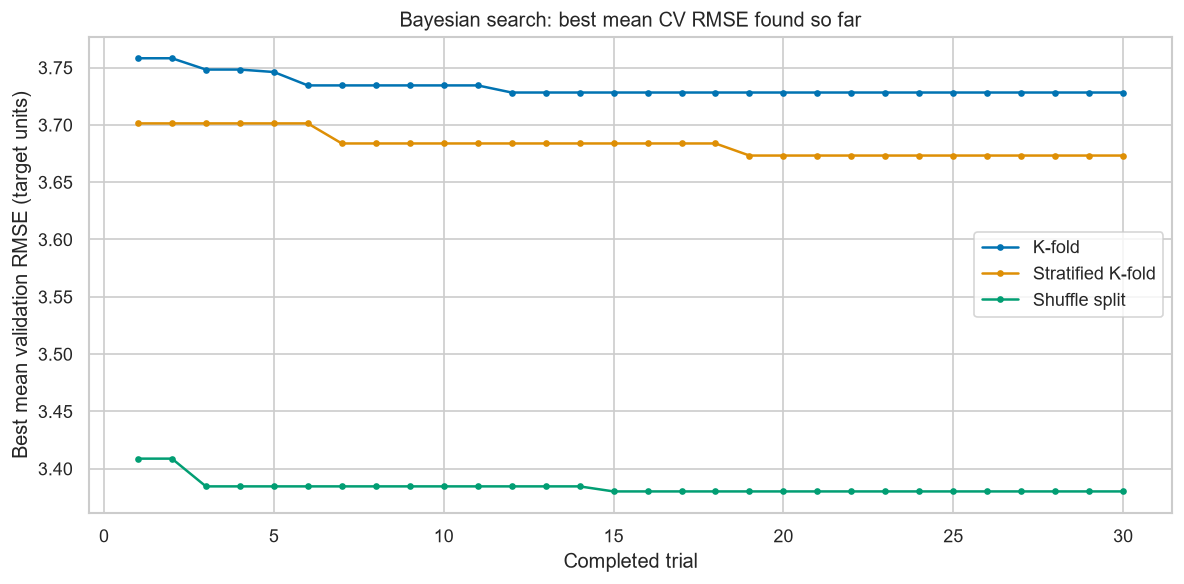

In [7]:
for scheme, splits in cv_splits.items():
    def objective(trial):
        params = {
            'n_estimators': trial.suggest_int('n_estimators', 100, 200, step=25),
            'max_depth': trial.suggest_categorical('max_depth', [None, 6, 12]),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 4),
        }
        model = clone(baseline).set_params(**params)
        with parallel_config(backend='threading'):
            scores = cross_validate(model, X_train, y_train, cv=splits, scoring=SCORING, n_jobs=N_JOBS, error_score='raise')
        values = positive_metrics(scores)
        trial.set_user_attr('fold_metrics', {m: values[m].tolist() for m in METRICS})
        return float(values['RMSE'].mean())

    study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=5))
    study.optimize(objective, n_trials=30, n_jobs=1, show_progress_bar=False)
    studies[scheme] = study
    values = {m: np.array(v) for m, v in study.best_trial.user_attrs['fold_metrics'].items()}
    record_folds(scheme, 'Bayesian TPE', values)
    candidates.append({'CV': scheme, 'Method': 'Bayesian TPE', 'Mean CV RMSE': study.best_value, 'Parameters': study.best_params})
    print(f'{scheme}: best parameters = {study.best_params}; CV RMSE = {study.best_value:.4f}')
    display(study.trials_dataframe()[['number', 'value', 'params_n_estimators', 'params_max_depth', 'params_min_samples_leaf']].sort_values('value').head(5).round(4))

fig, ax = plt.subplots(figsize=(10, 5))
for scheme, study in studies.items():
    values = np.array([t.value for t in study.trials])
    ax.plot(np.arange(1, len(values) + 1), np.minimum.accumulate(values), marker='.', label=scheme)
ax.set(title='Bayesian search: best mean CV RMSE found so far', xlabel='Completed trial', ylabel='Best mean validation RMSE (target units)')
ax.legend()
plt.tight_layout()
plt.show()

## 8. Compare validation results and select the final configuration
The summary contains all three validation schemes and all three methods. Each
cell reports the five split scores' mean and sample standard deviation (ddof=1).
The detailed table preserves every fold's R², MAE, MSE, and RMSE.

Tuned CV scores were used to choose parameters, so they can be optimistic; they
are not nested-CV estimates. Comparisons between CV schemes also involve different
validation observations. Choose the lowest mean CV RMSE among the six tuned
configurations before inspecting any hold-out scores. Stable iteration order breaks exact ties.

In [8]:
fold_metrics = pd.DataFrame(fold_records)
assert len(fold_metrics) == 45
assert np.isfinite(fold_metrics[METRICS].to_numpy()).all()
assert (fold_metrics[['MAE', 'MSE', 'RMSE']] >= 0).all().all()
assert np.allclose(fold_metrics['RMSE'] ** 2, fold_metrics['MSE'])
means = fold_metrics.groupby(['CV', 'Method'], sort=False)[METRICS].mean()
stds = fold_metrics.groupby(['CV', 'Method'], sort=False)[METRICS].std(ddof=1)
formatted = pd.DataFrame(index=means.index)
for m in METRICS:
    formatted[m + ' (mean ± SD)'] = [f'{a:.4f} ± {b:.4f}' for a, b in zip(means[m], stds[m])]
display(formatted)
display(fold_metrics.round(4))
candidate_table = pd.DataFrame(candidates).sort_values('Mean CV RMSE', kind='stable').reset_index(drop=True)
display(candidate_table.round(4))
winner = min(candidates, key=lambda c: c['Mean CV RMSE'])
print(f'Selected before test evaluation: {winner["Method"]} / {winner["CV"]}')
print(f'Parameters: {winner["Parameters"]}')

,,R2 (mean ± SD),MAE (mean ± SD),MSE (mean ± SD),RMSE (mean ± SD)
CV,Method,,,,
K-fold,Baseline,0.8294 ± 0.0626,2.4055 ± 0.2362,14.4042 ± 5.1440,3.7483 ± 0.6658
Stratified K-fold,Baseline,0.8386 ± 0.0323,2.4415 ± 0.0684,13.7518 ± 1.4168,3.7045 ± 0.1894
Shuffle split,Baseline,0.8649 ± 0.0401,2.3452 ± 0.2113,11.5813 ± 2.6407,3.3845 ± 0.3973
K-fold,Grid search,0.8308 ± 0.0611,2.3952 ± 0.2509,14.2997 ± 5.1052,3.7344 ± 0.6649
Stratified K-fold,Grid search,0.8413 ± 0.0325,2.4302 ± 0.0797,13.5259 ± 1.5175,3.6732 ± 0.2041
Shuffle split,Grid search,0.8650 ± 0.0417,2.3416 ± 0.2258,11.5570 ± 2.6830,3.3801 ± 0.4058
K-fold,Bayesian TPE,0.8314 ± 0.0600,2.3890 ± 0.2460,14.2359 ± 4.9680,3.7282 ± 0.6483
Stratified K-fold,Bayesian TPE,0.8413 ± 0.0325,2.4302 ± 0.0797,13.5259 ± 1.5175,3.6732 ± 0.2041
Shuffle split,Bayesian TPE,0.8650 ± 0.0417,2.3416 ± 0.2258,11.5570 ± 2.6830,3.3801 ± 0.4058


,CV,Method,Split,R2,MAE,MSE,RMSE
0,K-fold,Baseline,1,0.7763,2.4970,15.9065,3.9883
1,K-fold,Baseline,2,0.8983,2.3115,9.9914,3.1609
2,K-fold,Baseline,3,0.7510,2.7392,22.1219,4.7034
3,K-fold,Baseline,4,0.8640,2.3810,14.5497,3.8144
4,K-fold,Baseline,5,0.8574,2.0989,9.4517,3.0744
5,Stratified K-fold,Baseline,1,0.8166,2.4015,15.4738,3.9337
6,Stratified K-fold,Baseline,2,0.8749,2.5223,12.6870,3.5619
7,Stratified K-fold,Baseline,3,0.8629,2.4968,12.8634,3.5866
8,Stratified K-fold,Baseline,4,0.7966,2.3554,15.1152,3.8878
9,Stratified K-fold,Baseline,5,0.8422,2.4313,12.6196,3.5524


,CV,Method,Mean CV RMSE,Parameters
0,Shuffle split,Grid search,3.3801,"{'max_depth': 12, 'min_samples_leaf': 1, 'n_es..."
1,Shuffle split,Bayesian TPE,3.3801,"{'n_estimators': 100, 'max_depth': 12, 'min_sa..."
2,Stratified K-fold,Grid search,3.6732,"{'max_depth': 12, 'min_samples_leaf': 1, 'n_es..."
3,Stratified K-fold,Bayesian TPE,3.6732,"{'n_estimators': 200, 'max_depth': 12, 'min_sa..."
4,K-fold,Bayesian TPE,3.7282,"{'n_estimators': 175, 'max_depth': 12, 'min_sa..."
5,K-fold,Grid search,3.7344,"{'max_depth': 12, 'min_samples_leaf': 1, 'n_es..."


Selected before test evaluation: Grid search / Shuffle split
Parameters: {'max_depth': 12, 'min_samples_leaf': 1, 'n_estimators': 100}


## 9. Independent held-out evaluation
Refit the selected configuration and the untuned baseline on all 404 training
rows. Evaluate both on the same 102 previously excluded rows. These results are
reported as observed, even if tuning does not improve the test result. No model
or parameter changes follow test evaluation.

,R2,MAE,MSE,RMSE
Model,,,,
Baseline,0.8925,2.0367,7.8802,2.8072
Selected model,0.8907,2.0324,8.0145,2.8310


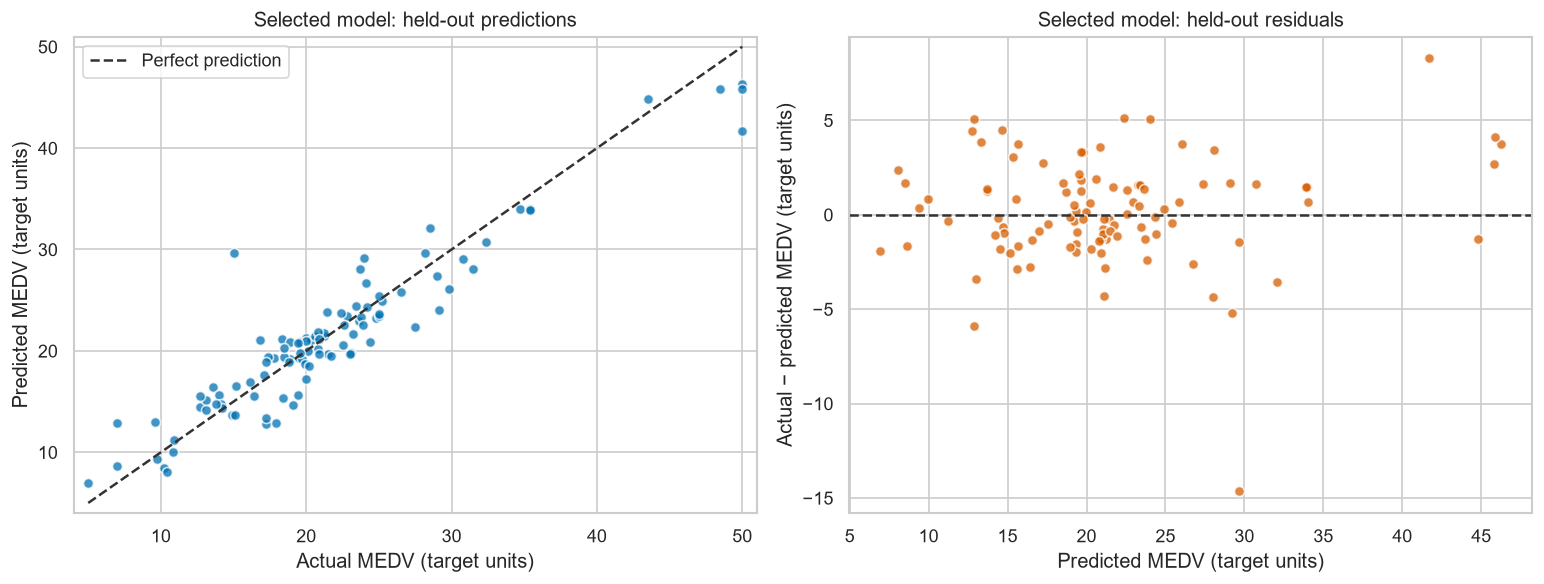

In [9]:
final_model = clone(baseline).set_params(**winner['Parameters']).fit(X_train, y_train)
baseline_model = clone(baseline).fit(X_train, y_train)
test_predictions = {'Baseline': baseline_model.predict(X_test), 'Selected model': final_model.predict(X_test)}
test_rows = []
for label, pred in test_predictions.items():
    assert np.isfinite(pred).all()
    test_rows.append({'Model': label, 'R2': r2_score(y_test, pred), 'MAE': mean_absolute_error(y_test, pred), 'MSE': mean_squared_error(y_test, pred), 'RMSE': root_mean_squared_error(y_test, pred)})
test_metrics = pd.DataFrame(test_rows).set_index('Model')
assert np.isfinite(test_metrics.to_numpy()).all()
assert np.allclose(test_metrics['RMSE'] ** 2, test_metrics['MSE'])
display(test_metrics.round(4))

selected_predictions = test_predictions['Selected model']
residuals = y_test.to_numpy() - selected_predictions
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, selected_predictions, color='#0072B2', alpha=0.75, edgecolors='white')
lo = min(y_test.min(), selected_predictions.min())
hi = max(y_test.max(), selected_predictions.max())
axes[0].plot([lo, hi], [lo, hi], linestyle='--', color='#333333', label='Perfect prediction')
axes[0].set(title='Selected model: held-out predictions', xlabel='Actual MEDV (target units)', ylabel='Predicted MEDV (target units)', xlim=(lo - 1, hi + 1), ylim=(lo - 1, hi + 1))
axes[0].legend()
axes[1].scatter(selected_predictions, residuals, color='#D55E00', alpha=0.75, edgecolors='white')
axes[1].axhline(0, color='#333333', linestyle='--')
axes[1].set(title='Selected model: held-out residuals', xlabel='Predicted MEDV (target units)', ylabel='Actual − predicted MEDV (target units)')
plt.tight_layout()
plt.show()

## 10. Insight
The following single paragraph is generated from the executed results, so its
reported figures remain consistent when the notebook is rerun.

In [10]:
selected = test_metrics.loc['Selected model']
reference = test_metrics.loc['Baseline']
delta = float(selected['RMSE'] - reference['RMSE'])
comparison = (f'reduced test RMSE by {-delta:.4f}' if delta < -1e-10 else f'increased test RMSE by {delta:.4f}' if delta > 1e-10 else 'matched baseline test RMSE')
winner_sd = stds.loc[(winner['CV'], winner['Method']), 'RMSE']
cv_range = means['RMSE'].agg(['min', 'max'])
insight = (
    f'The Boston target distribution is imbalanced across equal-width ranges, with positive skewness '
    f'of {target_skew:.3f} and a {imbalance_ratio:.0f}:1 ratio between the largest and smallest occupied bins, '
    'so sparsely represented target ranges may be harder to predict. '
    f'The three validation schemes produced mean RMSE values from {cv_range["min"]:.4f} to {cv_range["max"]:.4f} '
    'across baseline and tuned configurations, showing that both the split scheme and parameter choices affect the estimate. '
    f'Grid search and Bayesian TPE each tuned tree count, depth, and minimum leaf size; '
    f'the selected configuration came from {winner["Method"]} with {winner["CV"]}, '
    f'giving a selection CV RMSE of {winner["Mean CV RMSE"]:.4f} ± {winner_sd:.4f} across five splits. '
    f'On the independent 102-row test set it achieved R²={selected["R2"]:.4f}, MAE={selected["MAE"]:.4f}, '
    f'MSE={selected["MSE"]:.4f}, and RMSE={selected["RMSE"]:.4f}, and {comparison} '
    f'(baseline RMSE={reference["RMSE"]:.4f}). '
    'These results describe this fixed split of a small historical dataset; tuning scores are selection estimates, '
    'and overlapping ShuffleSplit samples mean split standard deviations are not confidence intervals. '
    f'The {int(y.eq(y.max()).sum())} observations at the observed maximum MEDV of {y.max():g} '
    'and uneven target coverage also limit conclusions about upper-range prediction.'
)
display(Markdown(insight))

The Boston target distribution is imbalanced across equal-width ranges, with positive skewness of 1.108 and a 22:1 ratio between the largest and smallest occupied bins, so sparsely represented target ranges may be harder to predict. The three validation schemes produced mean RMSE values from 3.3801 to 3.7483 across baseline and tuned configurations, showing that both the split scheme and parameter choices affect the estimate. Grid search and Bayesian TPE each tuned tree count, depth, and minimum leaf size; the selected configuration came from Grid search with Shuffle split, giving a selection CV RMSE of 3.3801 ± 0.4058 across five splits. On the independent 102-row test set it achieved R²=0.8907, MAE=2.0324, MSE=8.0145, and RMSE=2.8310, and increased test RMSE by 0.0238 (baseline RMSE=2.8072). These results describe this fixed split of a small historical dataset; tuning scores are selection estimates, and overlapping ShuffleSplit samples mean split standard deviations are not confidence intervals. The 16 observations at the observed maximum MEDV of 50 and uneven target coverage also limit conclusions about upper-range prediction.

## References
- [Scikit-learn: cross-validation, K-fold, stratification, and ShuffleSplit](https://scikit-learn.org/stable/modules/cross_validation.html)
- [Scikit-learn: RandomForestRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html)
- [Scikit-learn: GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)
- [Scikit-learn: regression metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics)
- [Optuna: TPESampler](https://optuna.readthedocs.io/en/stable/reference/samplers/generated/optuna.samplers.TPESampler.html)
- [Optuna: reproducibility](https://optuna.readthedocs.io/en/stable/faq.html#how-can-i-obtain-reproducible-optimization-results)

The local CSV is the data source. No external dataset is downloaded or substituted.